# PyTorch — L’essentiel du framework

## Objectifs

- Comprendre les tenseurs et `Autograd` ;
- construire un modèle avec `nn.Module` ;
- choisir une fonction de coût et un optimiseur ;
- écrire une boucle d’apprentissage et distinguer `train()` de `eval()` ;
- utiliser `Dataset` et `DataLoader` ;
- résoudre des problèmes de régression et de classification ;
- sauvegarder et recharger un modèle.

Les exercices sont suivis de leurs réponses et de cellules exécutables.

## 0. Préparation
Le notebook choisit CUDA lorsqu’il est disponible et fonctionne sinon sur CPU.

In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())
print("Appareil utilisé :", device)

PyTorch : 2.13.0+cpu
CUDA disponible : False
Appareil utilisé : cpu


## 1. Workflow général

**Données → Tensors → Modèle → Prédictions → Loss → Backward → Optimizer → Mise à jour**

À chaque étape d’entraînement, on calcule une prédiction, une perte, les gradients, puis on met à jour les paramètres.

In [2]:
# Schéma du cycle d’apprentissage :
# y_pred = model(X)
# loss = criterion(y_pred, y)
# optimizer.zero_grad()
# loss.backward()
# optimizer.step()

## 2. Les tenseurs
Un `Tensor` est le tableau multidimensionnel utilisé par PyTorch.

In [3]:
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
print("scalaire :", scalar, scalar.shape)
print("vecteur :", vector, vector.shape)
print("matrice :", matrix, matrix.shape)
print("dtype :", matrix.dtype, "ndim :", matrix.ndim)

scalaire : tensor(3.) torch.Size([])
vecteur : tensor([1., 2., 3.]) torch.Size([3])
matrice : tensor([[1., 2.],
        [3., 4.]]) torch.Size([2, 2])
dtype : torch.float32 ndim : 2


### Manipulation des tenseurs

In [4]:
x = torch.arange(12)
x2 = x.reshape(3, 4)
print("x :", x)
print("reshape(3, 4) :\n", x2)
print("colonne 1 :", x2[:, 1], "| ligne 0 :", x2[0, :])
A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[2., 0.], [1., 2.]])
print("A @ B :\n", A @ B)
print("moyenne :", A.mean().item(), "somme :", A.sum().item())

x : tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
reshape(3, 4) :
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
colonne 1 : tensor([1, 5, 9]) | ligne 0 : tensor([0, 1, 2, 3])
A @ B :
 tensor([[ 4.,  4.],
        [10.,  8.]])
moyenne : 2.5 somme : 10.0


## 3. CPU, GPU et `device`
Un modèle et ses données doivent être placés sur le même appareil.

In [5]:
x_device = torch.tensor([1.0, 2.0, 3.0], device=device)
print("appareil de x :", x_device.device)

appareil de x : cpu


## 4. Autograd
`Autograd` construit le graphe des opérations et calcule les dérivées.

In [6]:
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)
y = w * x + b
loss = (y - 10) ** 2
loss.backward()
print("y =", y.item(), "loss =", loss.item())
print("dLoss/dw =", w.grad.item(), "dLoss/db =", b.grad.item())

y = 7.0 loss = 9.0
dLoss/dw = -12.0 dLoss/db = -6.0


### Vérification analytique

Pour `y = wx + b` et `L = (y − 10)²`, les dérivées sont `∂L/∂w = 2(y − 10)x` et `∂L/∂b = 2(y − 10)`. Ici `y=7`, donc elles valent respectivement `−12` et `−6`.

In [7]:
y_val = 3.0 * 2.0 + 1.0
print("dL/dw analytique :", 2 * (y_val - 10) * 2.0)
print("dL/db analytique :", 2 * (y_val - 10))

dL/dw analytique : -12.0
dL/db analytique : -6.0


## 5. Un neurone avec `nn.Linear`
Un neurone linéaire calcule `z = somme(wᵢxᵢ) + b`.

In [8]:
linear = nn.Linear(3, 1)
x_linear = torch.tensor([[1.0, 2.0, 3.0]])
print("sortie :", linear(x_linear))
print("poids :", linear.weight)
print("biais :", linear.bias)

sortie : tensor([[1.5244]], grad_fn=<AddmmBackward0>)
poids : Parameter containing:
tensor([[ 0.4414,  0.4792, -0.1353]], requires_grad=True)
biais : Parameter containing:
tensor([0.5304], requires_grad=True)


## 6. Construire un réseau avec `nn.Module`

In [9]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16), nn.ReLU(),
            nn.Linear(16, 8), nn.ReLU(),
            nn.Linear(8, 3)
        )
    def forward(self, x):
        return self.net(x)

model_demo = MLP()
print(model_demo)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


## 7. Fonctions d’activation

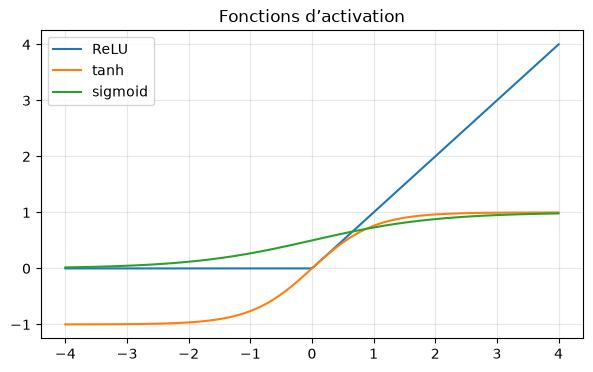

In [10]:
x_curve = torch.linspace(-4, 4, 200)
plt.figure(figsize=(7, 4))
plt.plot(x_curve, torch.relu(x_curve), label="ReLU")
plt.plot(x_curve, torch.tanh(x_curve), label="tanh")
plt.plot(x_curve, torch.sigmoid(x_curve), label="sigmoid")
plt.grid(alpha=.3); plt.legend(); plt.title("Fonctions d’activation"); plt.show()

## 8. Propagation avant
L’appel `model(X)` déclenche `forward(X)` et renvoie les prédictions.

In [11]:
X_demo = torch.randn(5, 4)
pred_demo = model_demo(X_demo)
print("forme entrée :", X_demo.shape, "| forme sortie :", pred_demo.shape)

forme entrée : torch.Size([5, 4]) | forme sortie : torch.Size([5, 3])


## 9. Fonctions de coût

- Régression : `nn.MSELoss()` ;
- classification multiclasses : `nn.CrossEntropyLoss()` ;
- classification binaire : `nn.BCEWithLogitsLoss()`.

Pour `CrossEntropyLoss`, fournir des logits bruts et des étiquettes entières, sans Softmax.

In [12]:
criterion_reg = nn.MSELoss()
print("MSE :", criterion_reg(torch.tensor([[2.], [4.]]), torch.tensor([[3.], [5.]])).item())
criterion_cls = nn.CrossEntropyLoss()
scores = torch.tensor([[2., 1., .5], [.2, .1, 2.]])
labels = torch.tensor([0, 2])
print("CrossEntropy :", criterion_cls(scores, labels).item())

MSE : 1.0
CrossEntropy : 0.36905235052108765


## 10. Optimiseurs
L’optimiseur utilise les gradients calculés pour mettre à jour les paramètres.

In [13]:
simple_model = nn.Linear(1, 1)
optimizer_demo = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
print(optimizer_demo)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


## 11. Boucle d’apprentissage
`zero_grad`, `backward` et `step` forment le cœur d’une boucle PyTorch.

In [14]:
torch.manual_seed(7)
X_toy = torch.randn(128, 1)
y_toy = 2 * X_toy + 1
toy_model = nn.Linear(1, 1)
toy_optimizer = torch.optim.Adam(toy_model.parameters(), lr=.05)
criterion = nn.MSELoss()
for epoch in range(301):
    toy_model.train()
    prediction = toy_model(X_toy)
    loss = criterion(prediction, y_toy)
    toy_optimizer.zero_grad()
    loss.backward()
    toy_optimizer.step()
    if epoch % 100 == 0:
        print(f"époque={epoch} perte={loss.item():.4f}")
print("w,b appris :", toy_model.weight.item(), toy_model.bias.item())

époque=0 perte=2.5747
époque=100 perte=0.0001
époque=200 perte=0.0000
époque=300 perte=0.0000
w,b appris : 2.0 1.0


## 12. `train()` et `eval()`

Ces modes modifient le comportement de couches comme Dropout et BatchNorm. `eval()` seul ne désactive pas les gradients ; pour l’inférence, on l’associe à `torch.inference_mode()`.

In [15]:
class DropoutDemo(nn.Module):
    def __init__(self):
        super().__init__(); self.dropout = nn.Dropout(p=.5)
    def forward(self, x): return self.dropout(x)
m = DropoutDemo(); ones = torch.ones(10)
m.train(); print("train() :", m(ones))
m.eval()
with torch.inference_mode(): print("eval() :", m(ones))

train() : tensor([0., 2., 2., 0., 2., 2., 0., 2., 2., 2.])
eval() : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


## 13. `Dataset` et `DataLoader`
`DataLoader` fournit des lots et peut mélanger les exemples d’entraînement.

In [16]:
X_data = torch.randn(100, 3); y_data = torch.randn(100, 1)
dataset = TensorDataset(X_data, y_data)
loader = DataLoader(dataset, batch_size=16, shuffle=True)
X_batch, y_batch = next(iter(loader))
print("lot X :", X_batch.shape, "| lot y :", y_batch.shape)

lot X : torch.Size([16, 3]) | lot y : torch.Size([16, 1])


# Partie pratique 1 — Régression linéaire

On génère des données autour de `y = 3x + 2 + bruit`.

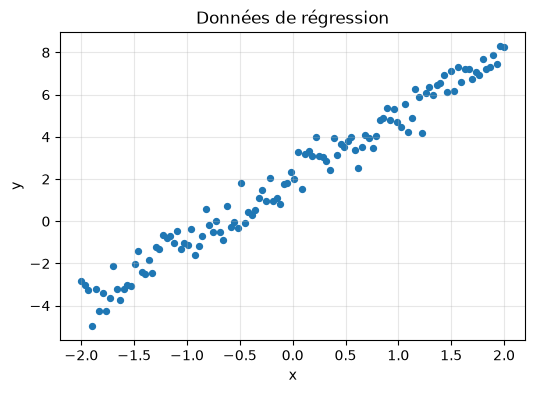

In [17]:
torch.manual_seed(42)
X_reg = torch.linspace(-2, 2, 120).unsqueeze(1)
y_reg = 3 * X_reg + 2 + .6 * torch.randn_like(X_reg)
plt.figure(figsize=(6, 4)); plt.scatter(X_reg, y_reg, s=18)
plt.title("Données de régression"); plt.xlabel("x"); plt.ylabel("y"); plt.grid(alpha=.3); plt.show()

## 14. Modèle, perte et optimiseur

In [18]:
model_reg = nn.Linear(1, 1)
criterion_reg = nn.MSELoss()
optimizer_reg = torch.optim.Adam(model_reg.parameters(), lr=.05)
print(model_reg)

Linear(in_features=1, out_features=1, bias=True)


## 15. Entraînement de la régression

perte finale : 0.3438
w appris : 2.989 b appris : 2.03


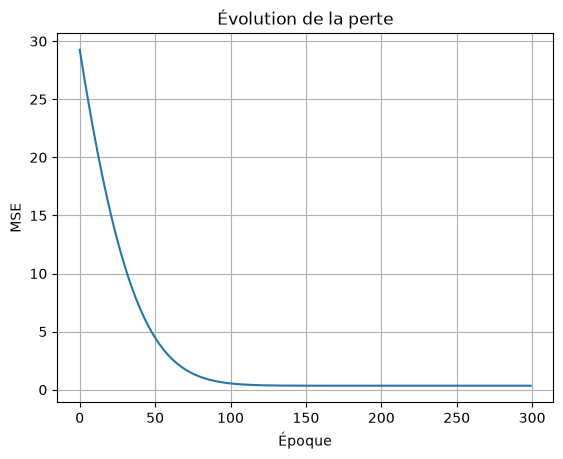

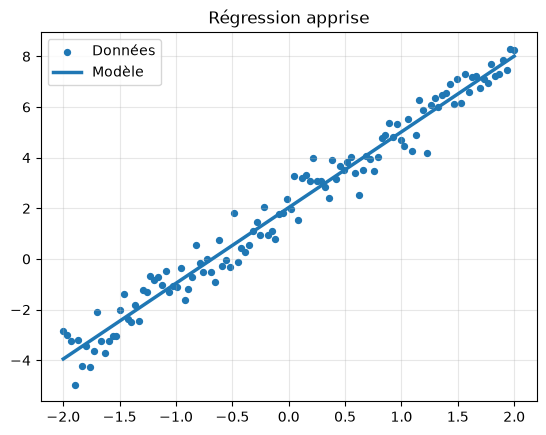

R² = 0.972


In [19]:
losses_reg = []
for epoch in range(300):
    model_reg.train()
    y_pred = model_reg(X_reg)
    loss = criterion_reg(y_pred, y_reg)
    optimizer_reg.zero_grad(); loss.backward(); optimizer_reg.step()
    losses_reg.append(loss.item())
print("perte finale :", round(losses_reg[-1], 4))
print("w appris :", round(model_reg.weight.item(), 3), "b appris :", round(model_reg.bias.item(), 3))
plt.plot(losses_reg); plt.xlabel("Époque"); plt.ylabel("MSE"); plt.title("Évolution de la perte"); plt.grid(); plt.show()
model_reg.eval()
with torch.inference_mode(): y_hat_reg = model_reg(X_reg)
plt.scatter(X_reg, y_reg, s=18, label="Données"); plt.plot(X_reg, y_hat_reg, lw=2.5, label="Modèle")
plt.legend(); plt.title("Régression apprise"); plt.grid(alpha=.3); plt.show()
ss_res = ((y_reg-y_hat_reg)**2).sum(); ss_tot=((y_reg-y_reg.mean())**2).sum()
print(f"R² = {1-ss_res/ss_tot:.3f}")

# Partie pratique 2 — Classification binaire

Deux classes de points en 2D ; le modèle renvoie deux logits par exemple.

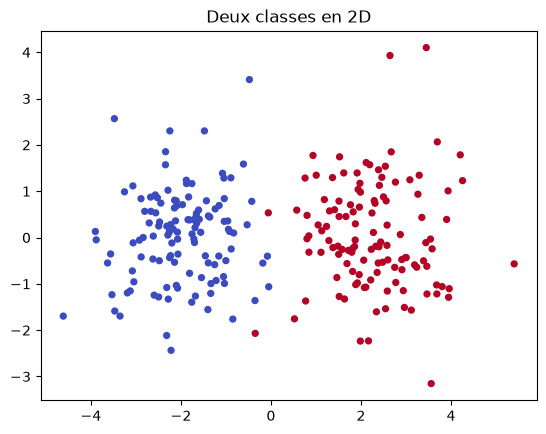

In [20]:
torch.manual_seed(0)
n = 120
class0 = torch.randn(n, 2) + torch.tensor([-2., 0.])
class1 = torch.randn(n, 2) + torch.tensor([2., 0.])
X_cls = torch.cat([class0, class1]); y_cls = torch.cat([torch.zeros(n, dtype=torch.long), torch.ones(n, dtype=torch.long)])
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, cmap="coolwarm", s=18); plt.title("Deux classes en 2D"); plt.show()

accuracy entraînement : 1.0


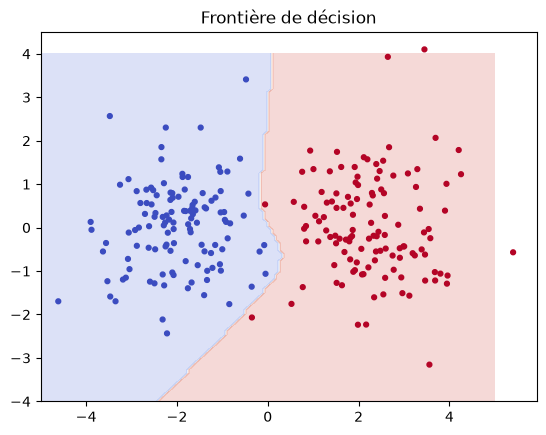

In [21]:
model_cls = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 2))
criterion_cls = nn.CrossEntropyLoss(); optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=.03)
for epoch in range(200):
    model_cls.train(); logits = model_cls(X_cls); loss = criterion_cls(logits, y_cls)
    optimizer_cls.zero_grad(); loss.backward(); optimizer_cls.step()
model_cls.eval()
with torch.inference_mode():
    pred_cls = model_cls(X_cls).argmax(dim=1)
    print("accuracy entraînement :", (pred_cls == y_cls).float().mean().item())
xx, yy = torch.meshgrid(torch.linspace(-5,5,120), torch.linspace(-4,4,100), indexing="xy")
grid = torch.stack([xx.ravel(), yy.ravel()], dim=1)
with torch.inference_mode(): zz=model_cls(grid).argmax(1).reshape(xx.shape)
plt.contourf(xx, yy, zz, alpha=.2, cmap="coolwarm"); plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, cmap="coolwarm", s=12); plt.title("Frontière de décision"); plt.show()

## 18. Sauvegarder et recharger un modèle

On sauvegarde le `state_dict`, puis on recrée la même architecture et on recharge ses paramètres.

In [22]:
from pathlib import Path
import tempfile
checkpoint_path = Path(tempfile.gettempdir()) / "modele_classification_pytorch.pth"
torch.save(model_cls.state_dict(), checkpoint_path)
new_model = nn.Sequential(nn.Linear(2,16), nn.ReLU(), nn.Linear(16,2))
new_model.load_state_dict(torch.load(checkpoint_path, map_location="cpu", weights_only=True))
model_cls_cpu = model_cls.cpu().eval(); new_model.eval()
with torch.inference_mode():
    print("prédictions identiques :", torch.equal(model_cls_cpu(X_cls).argmax(1), new_model(X_cls).argmax(1)))
model_cls.to(device)

prédictions identiques : True


Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=2, bias=True)
)

# Synthèse

Les principales briques sont `Tensor`, `nn.Module`, `forward`, fonction de coût, `zero_grad`, `backward`, `step`, `train/eval`, `Dataset/DataLoader` et la sauvegarde du `state_dict`. Le principe reste le même pour les architectures plus avancées.

# Exercices corrigés

## Exercice 1 — Régression : salaire selon l’ancienneté et l’expertise

Le salaire simulé suit `4000 + 600 × ancienneté + 1500 × expertise + bruit`. Nous entraînons une régression linéaire multiple et réservons 20 % des données au test.

Dimensions X et y : torch.Size([300, 2]) torch.Size([300, 1])
Salaire moyen : 15010.55 DH


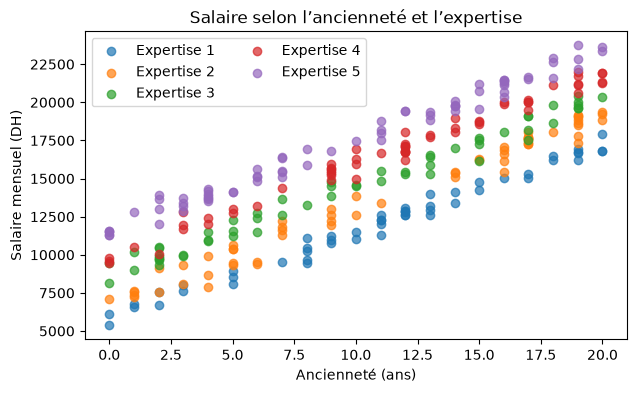

In [23]:
torch.manual_seed(42)
n_salary = 300
anciennete = torch.randint(0, 21, (n_salary, 1)).float()
expertise = torch.randint(1, 6, (n_salary, 1)).float()
bruit = torch.randn(n_salary, 1) * 500
salaires = 4000 + 600 * anciennete + 1500 * expertise + bruit
X_salary = torch.cat([anciennete, expertise], dim=1); y_salary = salaires
print("Dimensions X et y :", X_salary.shape, y_salary.shape)
print(f"Salaire moyen : {y_salary.mean().item():.2f} DH")
plt.figure(figsize=(7,4))
for niveau in range(1,6):
    m = X_salary[:,1] == niveau
    plt.scatter(X_salary[m,0], y_salary[m,0], label=f"Expertise {niveau}", alpha=.7)
plt.xlabel("Ancienneté (ans)"); plt.ylabel("Salaire mensuel (DH)"); plt.title("Salaire selon l’ancienneté et l’expertise"); plt.legend(ncol=2); plt.show()

### Réponses — données et préparation

`X` a la forme `(300, 2)` (ancienneté, expertise) et `y` `(300, 1)`. Le salaire moyen est calculé par la cellule ci-dessus. La couleur du nuage distingue les cinq niveaux d’expertise. Le jeu est séparé aléatoirement ; les statistiques de normalisation proviennent uniquement de l’entraînement pour éviter une fuite d’information.

In [24]:
indices = torch.randperm(n_salary); limite = int(.8*n_salary)
train_idx, test_idx = indices[:limite], indices[limite:]
X_train_salary, X_test_salary = X_salary[train_idx], X_salary[test_idx]
y_train_salary, y_test_salary = y_salary[train_idx]/1000, y_salary[test_idx]/1000
mean_salary = X_train_salary.mean(0, keepdim=True)
std_salary = X_train_salary.std(0, keepdim=True)
X_train_salary_norm = (X_train_salary-mean_salary)/std_salary
X_test_salary_norm = (X_test_salary-mean_salary)/std_salary
print("tailles train/test :", len(train_idx), len(test_idx))

tailles train/test : 240 60


### Réponses — modèle et entraînement

Le modèle reçoit 2 variables et produit 1 valeur : `nn.Linear(2, 1)`. On optimise la MSE par descente de gradient stochastique.

Époque 100 | MSE : 0.2391
Époque 200 | MSE : 0.2391
Époque 300 | MSE : 0.2391
Époque 400 | MSE : 0.2391
Époque 500 | MSE : 0.2391


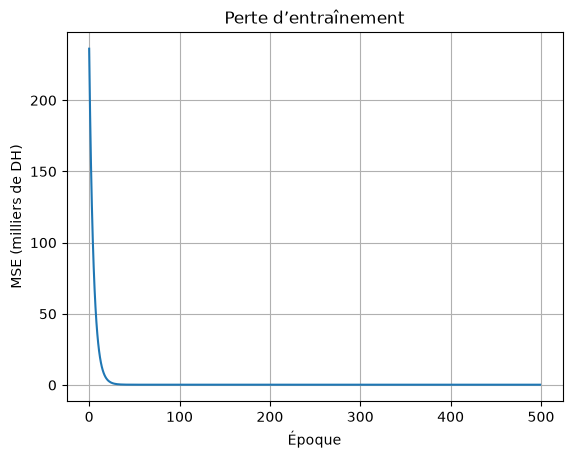

In [25]:
salary_model = nn.Linear(2, 1)
salary_loss_fn = nn.MSELoss()
salary_optimizer = torch.optim.SGD(salary_model.parameters(), lr=.05)
salary_history = []
for epoch in range(500):
    salary_model.train()
    predictions = salary_model(X_train_salary_norm)
    loss = salary_loss_fn(predictions, y_train_salary)
    salary_optimizer.zero_grad(); loss.backward(); salary_optimizer.step()
    salary_history.append(loss.item())
    if (epoch+1)%100 == 0: print(f"Époque {epoch+1} | MSE : {loss.item():.4f}")
plt.plot(salary_history); plt.xlabel("Époque"); plt.ylabel("MSE (milliers de DH)"); plt.title("Perte d’entraînement"); plt.grid(); plt.show()

### Réponses — évaluation et nouveau salarié

La MAE est calculée en dirhams sur les exemples de test. Le nouvel exemple est normalisé avec les mêmes moyenne et écart-type que l’entraînement, puis la prédiction est reconvertie en dirhams.

In [26]:
salary_model.eval()
with torch.inference_mode():
    pred_test_salary = salary_model(X_test_salary_norm)*1000
    true_test_salary = y_test_salary*1000
    mae_salary = (pred_test_salary-true_test_salary).abs().mean()
    new_employee = torch.tensor([[7., 4.]])
    new_employee_norm = (new_employee-mean_salary)/std_salary
    predicted_salary = salary_model(new_employee_norm).item()*1000
print(f"MAE test : {mae_salary.item():.2f} DH")
print(f"Salaire estimé pour 7 ans et expertise 4/5 : {predicted_salary:.2f} DH (valeur sans bruit : 14 200 DH)")
# Conversion des coefficients vers les unités originales : y est exprimé en milliers de DH.
with torch.inference_mode():
    coef_orig = salary_model.weight[0] / std_salary[0]
    intercept_orig = salary_model.bias[0] - (salary_model.weight[0] * mean_salary[0] / std_salary[0]).sum()
print("coefficients ancienneté/expertise (DH) :", (coef_orig*1000).tolist())
print("biais estimé (DH) :", intercept_orig.item()*1000)

MAE test : 381.64 DH
Salaire estimé pour 7 ans et expertise 4/5 : 14201.94 DH (valeur sans bruit : 14 200 DH)
coefficients ancienneté/expertise (DH) : [592.6640625, 1490.748779296875]
biais estimé (DH) : 4090.299606323242


### Réponses aux questions complémentaires — salaire

- À expertise constante, une année supplémentaire augmente le salaire d’environ **600 DH**, selon la règle génératrice.
- La perte ne vaut pas zéro parce que le bruit est aléatoire et non prévisible à partir des deux variables.
- Une ancienneté de 40 ans est hors de la plage observée (0 à 20) : l’extrapolation linéaire n’est pas validée et peut être peu fiable.
- Davantage de bruit augmente la dispersion et l’erreur de prédiction.
- Les coefficients ramenés aux unités originales sont affichés dans la cellule précédente ; ils devraient approcher 600, 1500 et 4000 DH. L’expertise numérique suppose un écart salarial constant entre les niveaux.

## Exercice 2 — Classification des fleurs Iris

Les quatre mesures sont longueur/largeur des sépales et longueur/largeur des pétales. Les étiquettes sont des entiers (`torch.long`), requis par `CrossEntropyLoss`. Le scaler est ajusté uniquement sur l’entraînement pour ne pas exploiter les statistiques du test.

In [27]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

torch.manual_seed(42)
iris = load_iris()
Xtr, Xte, ytr, yte = train_test_split(iris.data, iris.target, test_size=.2, random_state=42, stratify=iris.target)
iris_scaler = StandardScaler()
Xtr = torch.tensor(iris_scaler.fit_transform(Xtr), dtype=torch.float32)
Xte = torch.tensor(iris_scaler.transform(Xte), dtype=torch.float32)
ytr = torch.tensor(ytr, dtype=torch.long); yte = torch.tensor(yte, dtype=torch.long)
print("Dimensions :", Xtr.shape, ytr.shape)
print("Colonnes :", iris.feature_names)
print("dtype étiquettes :", ytr.dtype)

Dimensions : torch.Size([120, 4]) torch.Size([120])
Colonnes : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
dtype étiquettes : torch.int64


### Réponses — architecture et évaluation

Le réseau possède 4 entrées, une couche cachée ReLU de 16 unités et 3 logits de sortie (une par espèce). Aucun Softmax n’est ajouté car `CrossEntropyLoss` l’intègre dans son calcul. L’accuracy est la proportion de prédictions correctes.

Époque  20 | perte : 0.3695
Époque  40 | perte : 0.1923
Époque  60 | perte : 0.1063
Époque  80 | perte : 0.0724
Époque 100 | perte : 0.0590
Époque 120 | perte : 0.0525
Époque 140 | perte : 0.0488
Époque 160 | perte : 0.0463
Époque 180 | perte : 0.0445
Époque 200 | perte : 0.0432
Accuracy test : 100.0%
Matrice de confusion :
 [[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



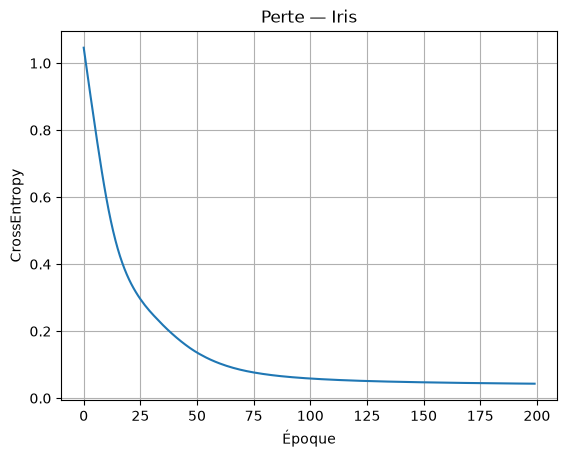

In [28]:
iris_model = nn.Sequential(nn.Linear(4,16), nn.ReLU(), nn.Linear(16,3))
iris_criterion = nn.CrossEntropyLoss(); iris_optimizer = torch.optim.Adam(iris_model.parameters(), lr=.01)
iris_losses=[]
for epoch in range(200):
    iris_model.train(); logits=iris_model(Xtr); loss=iris_criterion(logits,ytr)
    iris_optimizer.zero_grad(); loss.backward(); iris_optimizer.step(); iris_losses.append(loss.item())
    if (epoch+1)%20==0: print(f"Époque {epoch+1:3d} | perte : {loss.item():.4f}")
iris_model.eval()
with torch.inference_mode():
    iris_logits=iris_model(Xte); iris_pred=iris_logits.argmax(1); iris_accuracy=(iris_pred==yte).float().mean()
print(f"Accuracy test : {iris_accuracy.item():.1%}")
print("Matrice de confusion :\n", confusion_matrix(yte.numpy(), iris_pred.numpy()))
print(classification_report(yte.numpy(), iris_pred.numpy(), target_names=iris.target_names, zero_division=0))
plt.plot(iris_losses); plt.xlabel("Époque"); plt.ylabel("CrossEntropy"); plt.title("Perte — Iris"); plt.grid(); plt.show()

### Comparaison et nouvelle fleur — Iris

On compare avec une régression logistique (un `nn.Linear(4, 3)` sans couche cachée). Pour une nouvelle fleur, on applique `transform` du scaler déjà ajusté, puis on choisit le logit maximal.

In [29]:
linear_iris = nn.Linear(4,3); opt_linear_iris=torch.optim.Adam(linear_iris.parameters(), lr=.03)
for _ in range(300):
    linear_iris.train(); l=nn.functional.cross_entropy(linear_iris(Xtr),ytr)
    opt_linear_iris.zero_grad(); l.backward(); opt_linear_iris.step()
linear_iris.eval()
with torch.inference_mode():
    linear_acc=(linear_iris(Xte).argmax(1)==yte).float().mean().item()
    sample=np.array([[5.1,3.5,1.4,.2]],dtype=np.float32)
    sample_t=torch.tensor(iris_scaler.transform(sample),dtype=torch.float32)
    species=iris.target_names[iris_model(sample_t).argmax(1).item()]
print(f"Accuracy réseau avec couche cachée : {iris_accuracy.item():.1%}")
print(f"Accuracy nn.Linear(4,3) : {linear_acc:.1%}")
print("Espèce prédite pour [5.1, 3.5, 1.4, 0.2] :", species)

Accuracy réseau avec couche cachée : 100.0%
Accuracy nn.Linear(4,3) : 93.3%
Espèce prédite pour [5.1, 3.5, 1.4, 0.2] : setosa


## Exercice 3 — Classifier les chiffres MNIST avec un MLP

Nous utilisons des mini-lots de 64, cinq époques d’entraînement, puis les métriques accuracy, rappel, précision, F1 et la matrice de confusion. Les images mal classées sont aussi affichées.

In [30]:
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay

mnist_transform=transforms.ToTensor()
train_dataset=datasets.MNIST(root="./data", train=True, download=True, transform=mnist_transform)
test_dataset=datasets.MNIST(root="./data", train=False, download=True, transform=mnist_transform)
train_loader=DataLoader(train_dataset,batch_size=128,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=512,shuffle=False)
print("exemples train/test :",len(train_dataset),len(test_dataset))

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<00:56, 176kB/s]

  1%|          | 98.3k/9.91M [00:00<00:34, 286kB/s]

  2%|▏         | 164k/9.91M [00:00<00:25, 377kB/s] 

  3%|▎         | 262k/9.91M [00:00<00:17, 557kB/s]

...

 93%|█████████▎| 1.54M/1.65M [00:01<00:00, 2.25MB/s]

100%|██████████| 1.65M/1.65M [00:01<00:00, 1.51MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 4.60MB/s]

exemples train/test : 60000 10000


In [31]:
mnist_mlp=nn.Sequential(nn.Flatten(),nn.Linear(28*28,128),nn.ReLU(),nn.Linear(128,10)).to(device)
mnist_criterion=nn.CrossEntropyLoss(); mnist_optimizer=torch.optim.Adam(mnist_mlp.parameters(),lr=.001)
mlp_losses=[]
for epoch in range(5):
    mnist_mlp.train(); total_loss=0
    for images,labels in train_loader:
        images,labels=images.to(device),labels.to(device)
        mnist_optimizer.zero_grad(); outputs=mnist_mlp(images); loss=mnist_criterion(outputs,labels)
        loss.backward(); mnist_optimizer.step(); total_loss+=loss.item()*len(labels)
    mlp_losses.append(total_loss/len(train_dataset))
    print(f"Époque {epoch+1}/5 | perte : {mlp_losses[-1]:.4f}")

Époque 1/5 | perte : 0.4215


Époque 2/5 | perte : 0.2062


Époque 3/5 | perte : 0.1475


Époque 4/5 | perte : 0.1150


Époque 5/5 | perte : 0.0938
